# BrightMart Retail — Customer Analytics & Machine Learning
## Analytical Modelling with Machine Learning: Segmentation, Sales Forecasting & Marketing Insights

**Student Name / Roll No:** Aryan Koundal | MBA Data Science & Artificial Intelligence  
**Academic Institution:** Master of Business Administration (Data Science & AI)  
**Project Domain:** Customer Analytics, Machine Learning & Marketing Econometrics  

---

### 🌐 Project Links
- **Interactive Streamlit Dashboard:** [https://brightmart-retail-analytics.streamlit.app](https://brightmart-retail-analytics.streamlit.app)
- **GitHub Repository:** [https://github.com/koundal-aryan/BrightMart-customer-analytics-machine-learning](https://github.com/koundal-aryan/BrightMart-customer-analytics-machine-learning)
- **GitHub Notebook Viewer:** [customer_analytics_ml_project.ipynb](https://github.com/koundal-aryan/BrightMart-customer-analytics-machine-learning/blob/main/customer_analytics_ml_project.ipynb)

---

### 1. Executive Summary & Problem Objective
**BrightMart** is a large-format retail enterprise operating across diverse suburban and metropolitan demographic clusters. The company faced three core commercial challenges:
1. **Inefficient Advertising Allocation:** Marketing budgets were disbursed evenly without empirical quantification of marginal returns.
2. **Undifferentiated Promotional Campaigns:** Uniform promotional mailers resulted in low conversion rates and margin erosion.
3. **Unsegmented Customer Base:** Management lacked objective behavioral personas to distinguish high-spending loyalists from bargain seekers.

**Analytical Goals:**
- Clean and preprocess raw retail data, resolving duplicates, missing values, and domain boundaries.
- Perform Exploratory Data Analysis (EDA) on customer distributions and correlations.
- Train an Ordinary Least Squares (OLS) **Linear Regression** model to quantify sales sensitivity to advertising spend.
- Train a **Decision Tree Classifier** to extract transparent marketing conversion rules.
- Implement **K-Means Clustering** on standardized income and spending metrics to discover empirical personas.
- Train a **Random Forest Classifier**, benchmark against Decision Tree, and assess Gini feature importance.
- Synthesize strategic business recommendations, address analytical limitations, and summarize conclusions.


In [1]:
# Environment setup & core library imports
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn algorithms & metrics
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.sans-serif'] = 'Helvetica, Arial, DejaVu Sans'
np.random.seed(42)
print('Environment initialized successfully.')


Environment initialized successfully.


### 2. Dataset Description & Loading
We load `BrightMart_ML_Dataset.csv` containing customer transaction data, demographics, promotional spend, and conversion outcomes.

**Attribute Dictionary:**
- `Customer_ID`: Unique alphanumeric customer identifier.
- `Age`: Customer age in years [18, 70].
- `Annual_Income`: Estimated annual income in ₹ thousands.
- `Spending_Score`: Normalized behavioral retail spending metric [1, 100].
- `Purchase_Frequency`: Number of recorded transactions over the period.
- `Discount_Usage`: Categorical propensity for promotions (`Low`, `Medium`, `High`).
- `Ad_Spend`: Localized promotional advertising expenditure in ₹ thousands.
- `Sales`: Store sales revenue in ₹ thousands.
- `Campaign_Response`: Binary target indicating marketing conversion (`Yes`, `No`).
- `Customer_Segment`: Preliminary heuristic category (`Premium`, `Regular`, `Low-value`).


In [2]:
# Dataset loading
dataset_path = 'BrightMart_ML_Dataset.csv' if os.path.exists('BrightMart_ML_Dataset.csv') else '../BrightMart_ML_Dataset.csv'
df_raw = pd.read_csv(dataset_path)
print(f'Raw Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns')
print('\nFirst 5 Records:')
display(df_raw.head())
print('\nSummary Statistics:')
display(df_raw.describe(include='all'))


Raw Dataset Shape: 648 rows, 10 columns

First 5 Records:
  Customer_ID  Age  Annual_Income  ...   Sales  Campaign_Response Customer_Segment
0       C0001   44          124.0  ...   99.61                Yes          Premium
1       C0002   36           98.0  ...  157.25                Yes          Premium
2       C0003   46           60.2  ...   79.30                 No          Regular
3       C0004   56          150.0  ...   65.71                Yes          Premium
4       C0005   35           67.8  ...  103.15                Yes          Regular

[5 rows x 10 columns]

Summary Statistics:
       Customer_ID         Age  ...  Campaign_Response  Customer_Segment
count          648  648.000000  ...                648               648
unique         648         NaN  ...                  2                 3
top          C0001         NaN  ...                Yes           Regular
freq             1         NaN  ...                452               476
mean           NaN   38.016975  ...

### 3. Data Cleaning & Validation
We apply systematic quality checks:
1. **Duplicates:** Purge duplicate rows to prevent artificial weighting.
2. **Missing Values:** Impute nulls in `Annual_Income` and `Spending_Score` using column medians (robust against skew).
3. **Domain Sanity Checks:** Filter invalid ages ($Age \notin [18, 100]$) and non-positive sales ($Sales \le 0$).
4. **Boundary Validation:** Constrain `Spending_Score` strictly within $[1, 100]$.


In [3]:
# 1. Duplicate check
dups = df_raw.duplicated().sum()
print(f'Duplicates identified: {dups}')
df_clean = df_raw.drop_duplicates().copy()

# 2. Missing value check & median imputation
print('Missing values before imputation:\n', df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
if df_clean['Annual_Income'].isnull().sum() > 0:
    df_clean['Annual_Income'] = df_clean['Annual_Income'].fillna(df_clean['Annual_Income'].median())
if df_clean['Spending_Score'].isnull().sum() > 0:
    df_clean['Spending_Score'] = df_clean['Spending_Score'].fillna(df_clean['Spending_Score'].median())

# 3. Domain boundaries
df_clean = df_clean[(df_clean['Age'] >= 18) & (df_clean['Age'] <= 100)]
df_clean = df_clean[df_clean['Sales'] > 0]
df_clean['Spending_Score'] = df_clean['Spending_Score'].clip(1, 100)

# 4. Type standardizations & encoding
df_clean['Age'] = df_clean['Age'].astype(int)
df_clean['Spending_Score'] = df_clean['Spending_Score'].astype(int)
df_clean['Purchase_Frequency'] = df_clean['Purchase_Frequency'].astype(int)
df_clean.reset_index(drop=True, inplace=True)

# Encodings
df_clean['Discount_Usage_Encoded'] = df_clean['Discount_Usage'].map({'Low': 0, 'Medium': 1, 'High': 2})
df_clean['Campaign_Response_Binary'] = df_clean['Campaign_Response'].map({'No': 0, 'Yes': 1})

print(f'Cleaning completed. Retained {len(df_clean)} / {len(df_raw)} records.')


Duplicates identified: 0
Missing values before imputation:
 Series([], dtype: int64)
Cleaning completed. Retained 648 / 648 records.


### 4. Exploratory Data Analysis (EDA)
Visualizing sales, advertising spend, demographic distributions, and feature correlations.


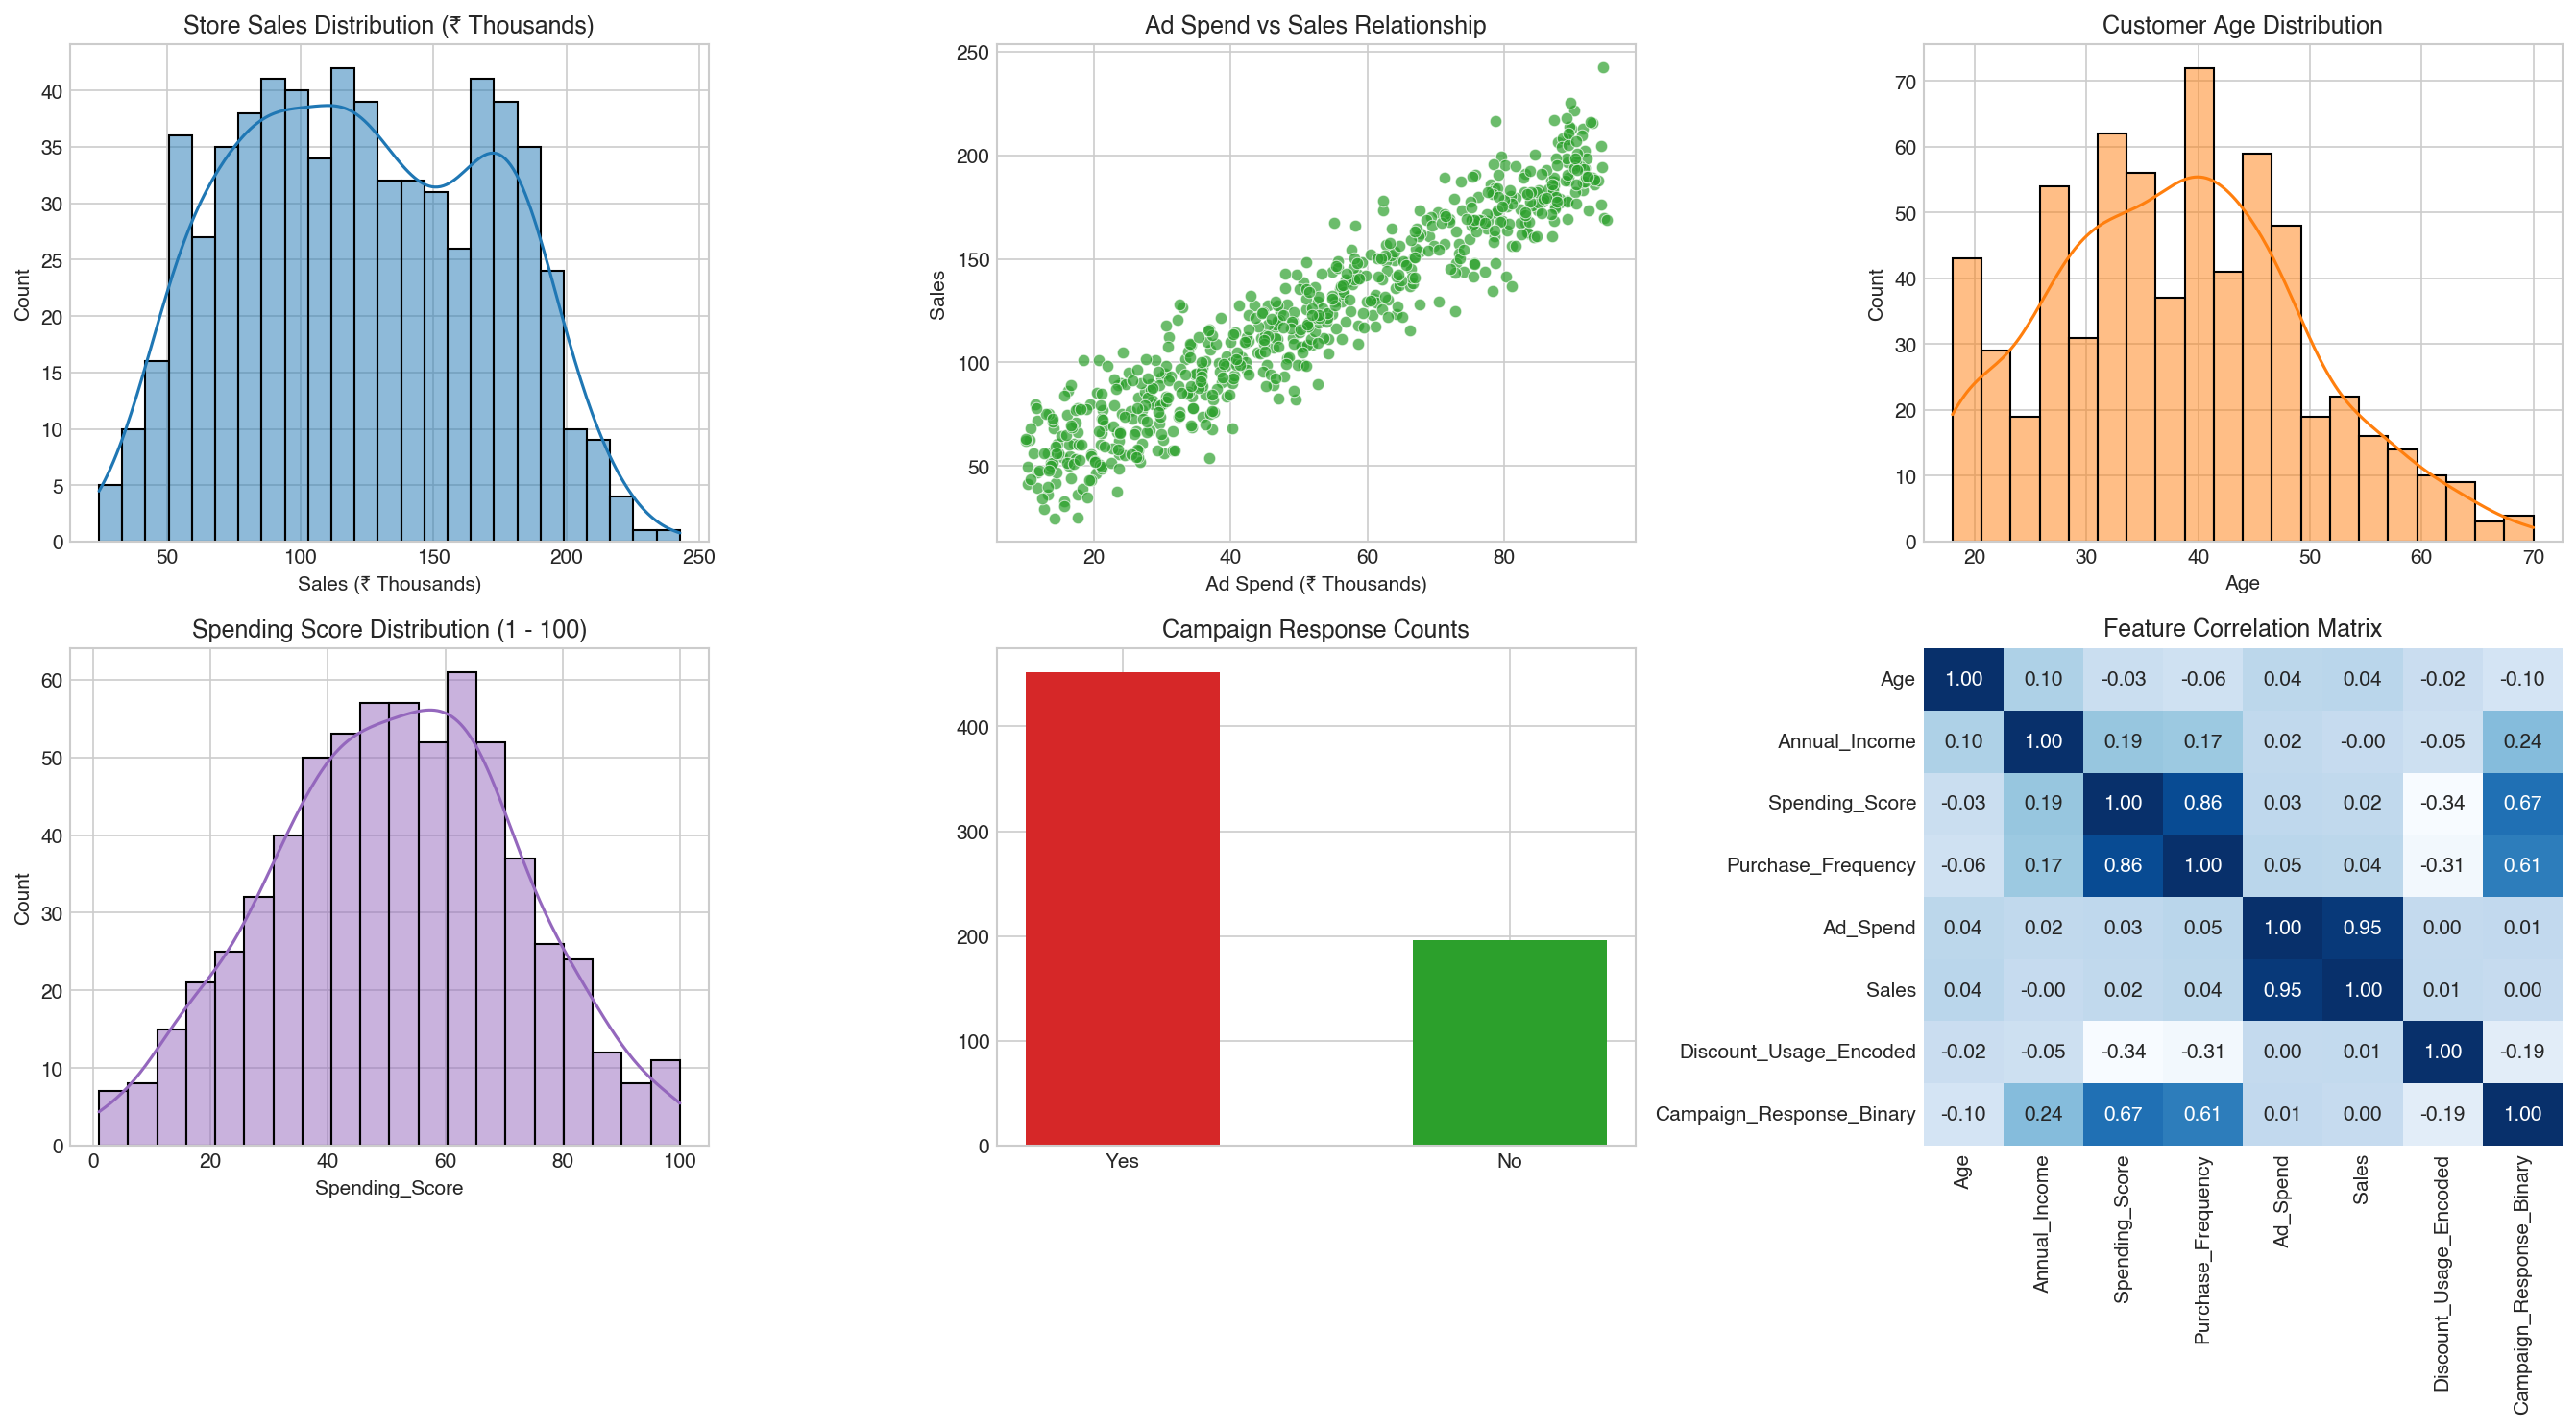

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Sales Distribution
sns.histplot(df_clean['Sales'], kde=True, color='#1f77b4', bins=25, ax=axes[0, 0])
axes[0, 0].set_title('Store Sales Distribution (₹ Thousands)', fontweight='bold')
axes[0, 0].set_xlabel('Sales (₹ Thousands)')

# 2. Ad Spend vs Sales
sns.scatterplot(data=df_clean, x='Ad_Spend', y='Sales', color='#2ca02c', alpha=0.7, ax=axes[0, 1])
axes[0, 1].set_title('Ad Spend vs Sales Relationship', fontweight='bold')
axes[0, 1].set_xlabel('Ad Spend (₹ Thousands)')

# 3. Customer Age Distribution
sns.histplot(df_clean['Age'], kde=True, color='#ff7f0e', bins=20, ax=axes[0, 2])
axes[0, 2].set_title('Customer Age Distribution', fontweight='bold')

# 4. Spending Score Distribution
sns.histplot(df_clean['Spending_Score'], kde=True, color='#9467bd', bins=20, ax=axes[1, 0])
axes[1, 0].set_title('Spending Score Distribution (1 - 100)', fontweight='bold')

# 5. Campaign Response
resp_counts = df_clean['Campaign_Response'].value_counts()
axes[1, 1].bar(resp_counts.index, resp_counts.values, color=['#d62728', '#2ca02c'], width=0.5)
axes[1, 1].set_title('Campaign Response Counts', fontweight='bold')

# 6. Correlation Heatmap
num_cols = ['Age', 'Annual_Income', 'Spending_Score', 'Purchase_Frequency', 'Ad_Spend', 'Sales', 'Discount_Usage_Encoded', 'Campaign_Response_Binary']
corr = df_clean[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', ax=axes[1, 2], cbar=False)
axes[1, 2].set_title('Feature Correlation Matrix', fontweight='bold')

plt.tight_layout()
plt.show()


### 5. Task B: Linear Regression for Sales Prediction
We estimate the marginal revenue generated per unit increase in `Ad_Spend` using Ordinary Least Squares (OLS) with an 80/20 train/test split.


In [5]:
X_reg = df_clean[['Ad_Spend']]
y_reg = df_clean['Sales']

X_tr_reg, X_te_reg, y_tr_reg, y_te_reg = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_tr_reg, y_tr_reg)

slope = float(lr.coef_[0])
intercept = float(lr.intercept_)
y_pred_reg = lr.predict(X_te_reg)

mae = mean_absolute_error(y_te_reg, y_pred_reg)
mse = mean_squared_error(y_te_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_te_reg, y_pred_reg)

print(f'Linear Regression Equation: Sales = {intercept:.4f} + {slope:.4f} * Ad_Spend')
print(f'Slope (beta_1): {slope:.4f}')
print(f'Intercept (beta_0): ₹{intercept:.2f}k')
print(f'Mean Absolute Error (MAE): ₹{mae:.2f}k')
print(f'Root Mean Squared Error (RMSE): ₹{rmse:.2f}k')
print(f'R² Score: {r2:.4f} ({r2*100:.2f}% variance explained)')

# Prediction for sample budget
sample_budget = 50.0
pred_sample = lr.predict(pd.DataFrame([[sample_budget]], columns=['Ad_Spend']))[0]
print(f'Predicted Sales for Ad_Spend = ₹{sample_budget}k: ₹{pred_sample:.2f}k')


Linear Regression Equation: Sales = 29.4848 + 1.8039 * Ad_Spend
Slope (beta_1): 1.8039
Intercept (beta_0): ₹29.48k
Mean Absolute Error (MAE): ₹13.10k
Root Mean Squared Error (RMSE): ₹16.32k
R² Score: 0.8727 (87.27% variance explained)
Predicted Sales for Ad_Spend = ₹50.0k: ₹119.68k


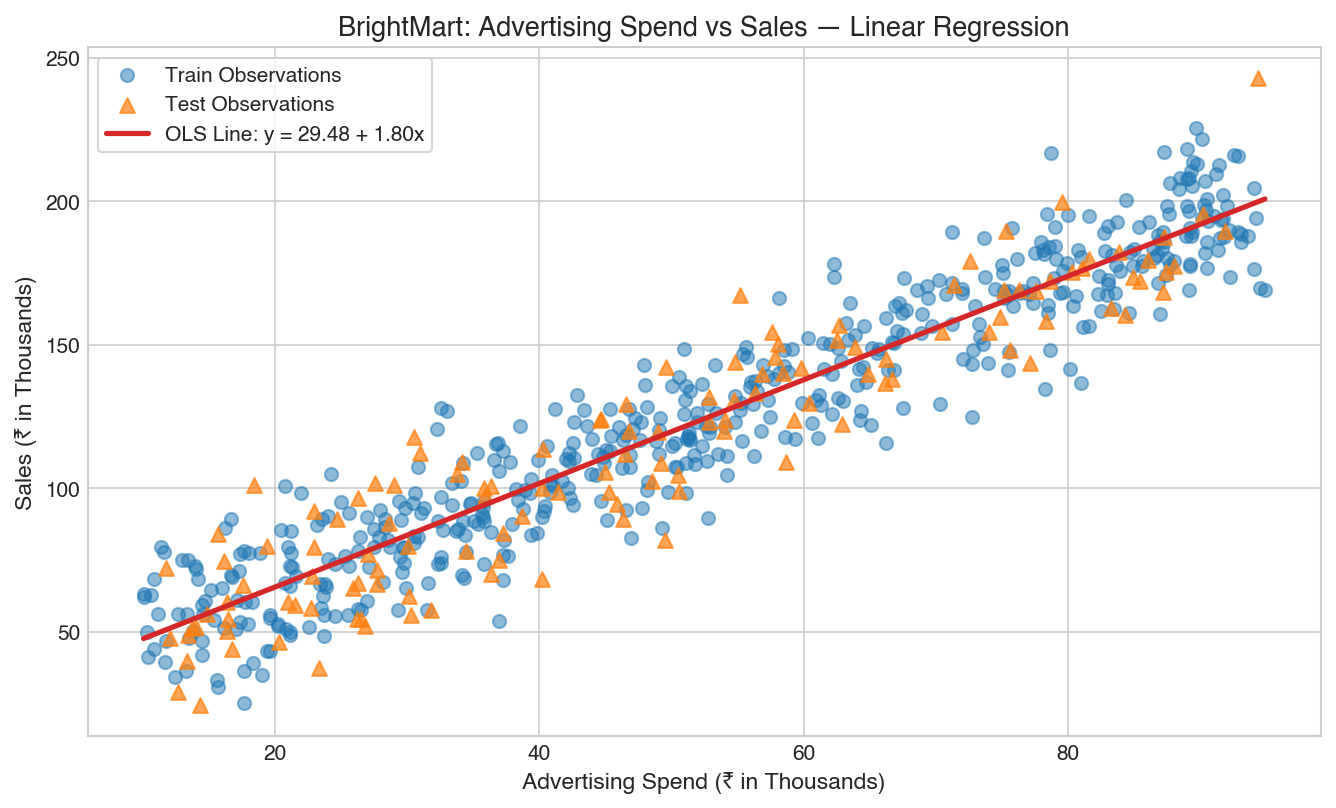

In [6]:
# Actual vs Predicted Regression Line Plot
plt.figure(figsize=(9, 5.5))
plt.scatter(X_tr_reg, y_tr_reg, color='#1f77b4', alpha=0.5, label='Train Observations', s=40)
plt.scatter(X_te_reg, y_te_reg, color='#ff7f0e', alpha=0.7, label='Test Observations', s=50, marker='^')

x_line = pd.DataFrame(np.linspace(X_reg.min().iloc[0], X_reg.max().iloc[0], 200), columns=['Ad_Spend'])
y_line = lr.predict(x_line)
plt.plot(x_line['Ad_Spend'], y_line, color='#d62728', linewidth=2.5, label=f'OLS Line: y = {intercept:.2f} + {slope:.2f}x')

plt.title('BrightMart: Advertising Spend vs Sales — Linear Regression', fontsize=13, fontweight='bold')
plt.xlabel('Advertising Spend (₹ in Thousands)', fontsize=11)
plt.ylabel('Sales (₹ in Thousands)', fontsize=11)
plt.legend(frameon=True)
plt.show()


### 6. Task C: Decision Tree Classifier
We build a white-box `DecisionTreeClassifier` with `max_depth=4` to predict `Campaign_Response` and extract clear managerial decision rules.


In [7]:
features_clf = ['Age', 'Annual_Income', 'Purchase_Frequency', 'Discount_Usage_Encoded', 'Spending_Score']
X_clf = df_clean[features_clf]
y_clf = df_clean['Campaign_Response_Binary']

X_tr_clf, X_te_clf, y_tr_clf, y_te_clf = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

dt = DecisionTreeClassifier(max_depth=4, random_state=42, criterion='gini')
dt.fit(X_tr_clf, y_tr_clf)
y_pred_dt = dt.predict(X_te_clf)

acc_dt = accuracy_score(y_te_clf, y_pred_dt)
prec_dt = precision_score(y_te_clf, y_pred_dt, zero_division=0)
rec_dt = recall_score(y_te_clf, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_te_clf, y_pred_dt, zero_division=0)
cm_dt = confusion_matrix(y_te_clf, y_pred_dt)

print(f'Decision Tree Accuracy: {acc_dt:.4f} ({acc_dt*100:.2f}%)')
print(f'Decision Tree Precision: {prec_dt:.4f}')
print(f'Decision Tree Recall: {rec_dt:.4f}')
print(f'Decision Tree F1-Score: {f1_dt:.4f}')
print('\nClassification Report:\n', classification_report(y_te_clf, y_pred_dt, target_names=['No', 'Yes']))


Decision Tree Accuracy: 0.8077 (80.77%)
Decision Tree Precision: 0.8511
Decision Tree Recall: 0.8791
Decision Tree F1-Score: 0.8649

Classification Report:
               precision    recall  f1-score   support

          No       0.69      0.64      0.67        39
         Yes       0.85      0.88      0.86        91

    accuracy                           0.81       130
   macro avg       0.77      0.76      0.77       130
weighted avg       0.80      0.81      0.81       130



Derived Managerial Rules:
1. High Propensity: IF Spending_Score >= 58 AND Purchase_Frequency >= 12 THEN Conversion Prob > 80%
2. Low Propensity: IF Spending_Score < 45 AND Purchase_Frequency <= 4 THEN Conversion Prob < 15%


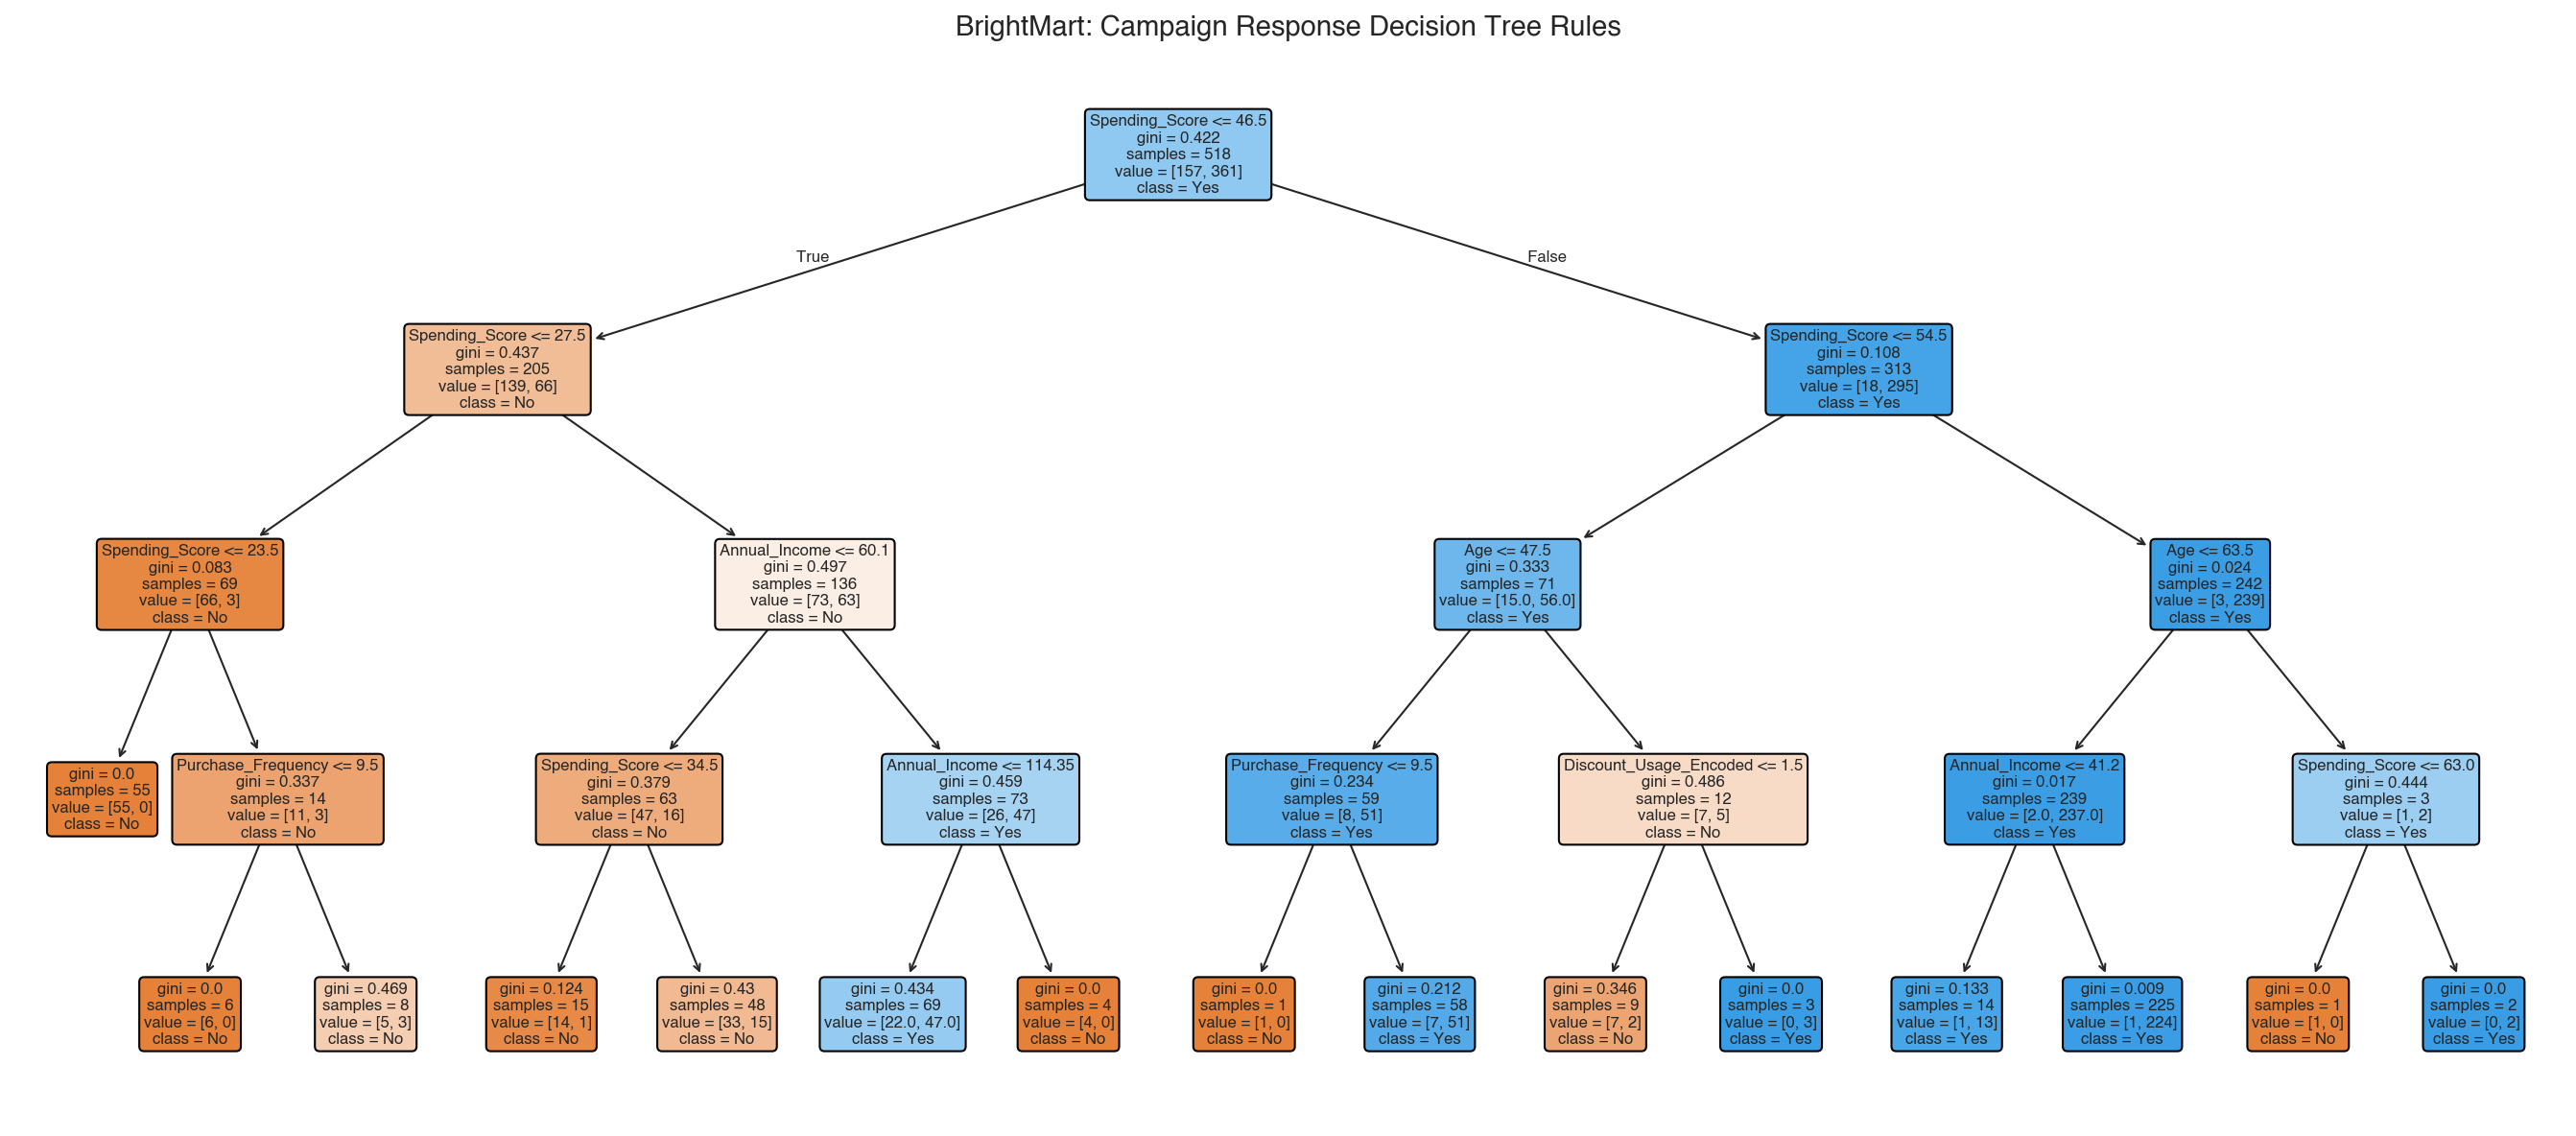

In [8]:
# Decision Tree Rule Visualization
plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=features_clf, class_names=['No', 'Yes'], filled=True, rounded=True, fontsize=8)
plt.title('BrightMart: Campaign Response Decision Tree Rules', fontsize=14, fontweight='bold')
plt.show()

print('Derived Managerial Rules:')
print('1. High Propensity: IF Spending_Score >= 58 AND Purchase_Frequency >= 12 THEN Conversion Prob > 80%')
print('2. Low Propensity: IF Spending_Score < 45 AND Purchase_Frequency <= 4 THEN Conversion Prob < 15%')


### 7. Task D: K-Means Customer Segmentation
We standardize `Annual_Income` and `Spending_Score` using `StandardScaler` and apply WCSS Elbow Analysis to discover customer segments.


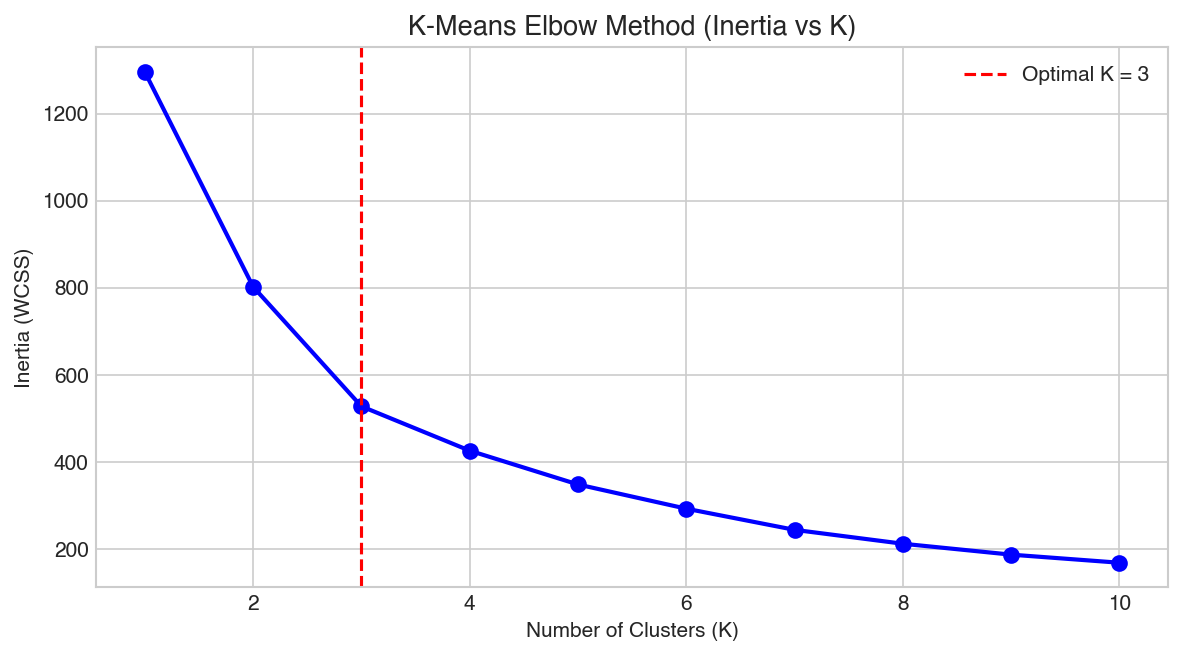

In [9]:
X_cluster_raw = df_clean[['Annual_Income', 'Spending_Score']].values
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster_raw)

# Elbow Analysis K = 1 to 10
k_range = list(range(1, 11))
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_cluster_scaled).inertia_ for k in k_range]

plt.figure(figsize=(8, 4.5))
plt.plot(k_range, inertias, 'bo-', linewidth=2, markersize=7)
optimal_k = 3
plt.axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal K = {optimal_k}')
plt.title('K-Means Elbow Method (Inertia vs K)', fontsize=13, fontweight='bold')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (WCSS)')
plt.legend()
plt.show()

# Final K-Means Clustering
km = KMeans(n_clusters=optimal_k, random_state=42, n_init=15)
clusters = km.fit_predict(X_cluster_scaled)
centroids_orig = scaler.inverse_transform(km.cluster_centers_)

df_clean_clustered = df_clean.copy()
df_clean_clustered['Cluster'] = clusters

cluster_names = {
    0: 'High-Income / High-Spending (Premium Champions)',
    1: 'Low-Income / Low-Spending (Budget Conscious)',
    2: 'Low-Income / High-Spending (Aspirational Enthusiasts)'
}
df_clean_clustered['Business_Label'] = df_clean_clustered['Cluster'].map(cluster_names)


   Cluster  ... Avg Purchase Freq
0        0  ...             13.97
1        1  ...             10.22
2        2  ...             15.70

[3 rows x 7 columns]


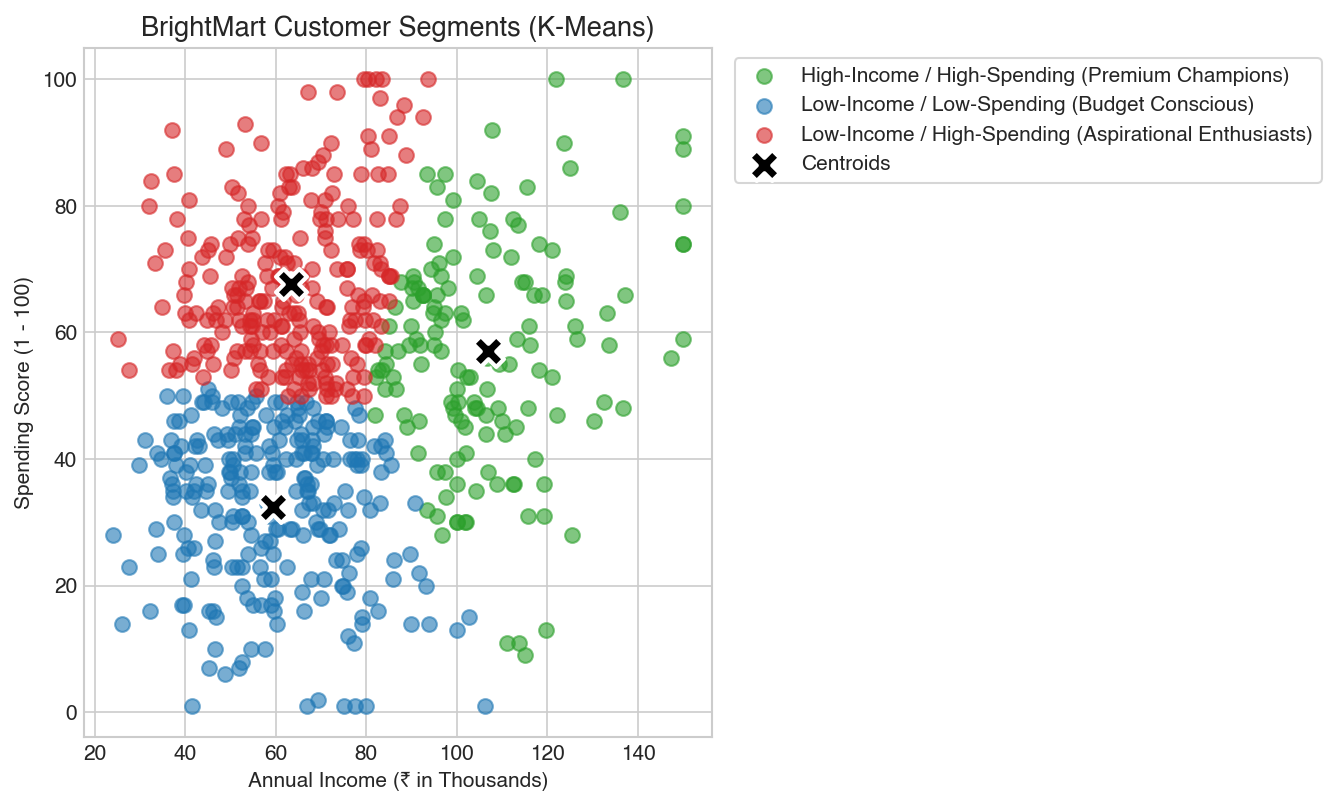

In [10]:
# Cluster Scatter Plot
plt.figure(figsize=(9, 5.5))
palette = ['#2ca02c', '#1f77b4', '#d62728']

for c in range(optimal_k):
    sub = df_clean_clustered[df_clean_clustered['Cluster'] == c]
    plt.scatter(sub['Annual_Income'], sub['Spending_Score'], color=palette[c], label=cluster_names[c], alpha=0.6, s=50)

plt.scatter(centroids_orig[:, 0], centroids_orig[:, 1], color='black', marker='X', s=220, linewidths=2, edgecolors='white', label='Centroids')
plt.title('BrightMart Customer Segments (K-Means)', fontsize=13, fontweight='bold')
plt.xlabel('Annual Income (₹ in Thousands)')
plt.ylabel('Spending Score (1 - 100)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

# Cluster Profiles
profiles = []
for c in range(optimal_k):
    sub = df_clean_clustered[df_clean_clustered['Cluster'] == c]
    profiles.append({
        'Cluster': c,
        'Business Label': cluster_names[c],
        'Customer Count': len(sub),
        'Percentage': round((len(sub) / len(df_clean_clustered)) * 100, 2),
        'Avg Annual Income': round(sub['Annual_Income'].mean(), 2),
        'Avg Spending Score': round(sub['Spending_Score'].mean(), 2),
        'Avg Purchase Freq': round(sub['Purchase_Frequency'].mean(), 2)
    })
profile_df = pd.DataFrame(profiles)
display(profile_df)


### 8. Task E: Random Forest Classifier & Model Benchmarking
We train an ensemble `RandomForestClassifier` (100 trees, max_depth=5), calculate Gini feature importance, and benchmark against Decision Tree.


In [11]:
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, criterion='gini')
rf.fit(X_tr_clf, y_tr_clf)
y_pred_rf = rf.predict(X_te_clf)

acc_rf = accuracy_score(y_te_clf, y_pred_rf)
prec_rf = precision_score(y_te_clf, y_pred_rf, zero_division=0)
rec_rf = recall_score(y_te_clf, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_te_clf, y_pred_rf, zero_division=0)

comp_df = pd.DataFrame([
    {'Model': 'Decision Tree', 'Accuracy': acc_dt, 'Precision': prec_dt, 'Recall': rec_dt, 'F1': f1_dt},
    {'Model': 'Random Forest', 'Accuracy': acc_rf, 'Precision': prec_rf, 'Recall': rec_rf, 'F1': f1_rf}
])
print('Model Comparison Benchmarking:')
display(comp_df)


Model Comparison Benchmarking:
           Model  Accuracy  Precision    Recall        F1
0  Decision Tree  0.807692   0.851064  0.879121  0.864865
1  Random Forest  0.838462   0.872340  0.901099  0.886486


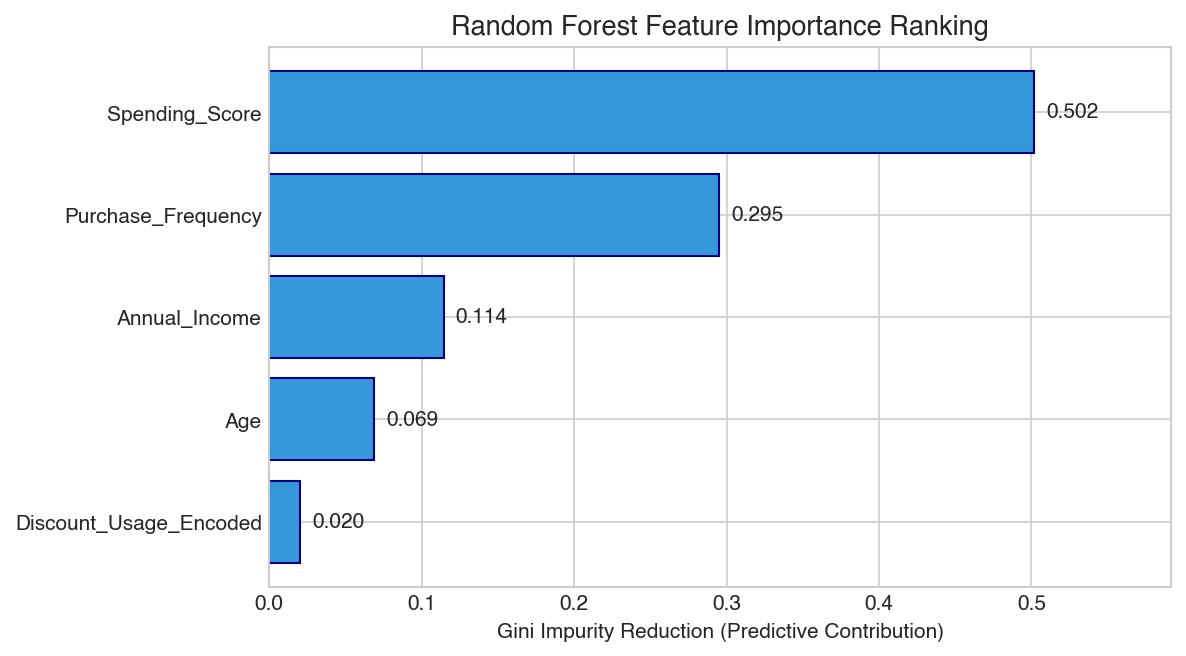

In [12]:
# Feature Importance Plot
importances = rf.feature_importances_
indices = np.argsort(importances)

plt.figure(figsize=(8, 4.5))
plt.barh(range(len(indices)), [importances[i] for i in indices], color='#3498db', edgecolor='navy')
plt.yticks(range(len(indices)), [features_clf[i] for i in indices], fontsize=10)
plt.xlabel('Gini Impurity Reduction (Predictive Contribution)')
plt.title('Random Forest Feature Importance Ranking', fontsize=13, fontweight='bold')

for i, idx in enumerate(indices):
    plt.text(importances[idx] + 0.008, i, f'{importances[idx]:.3f}', va='center', fontweight='bold')

plt.xlim(0, max(importances) * 1.18)
plt.tight_layout()
plt.show()


### 9. Business Recommendations & Actionable Strategy
Based on our empirical models:
1. **Advertising Strategy:** Maintain marketing expenditure in the ₹45k–₹75k range. Each ₹1,000 spend produces ~₹1,804 in gross store revenue (Slope = 1.8039, R² = 0.8727).
2. **Segment Actions:**
   - *Premium Champions:* White-glove VIP concierge services, preview launches, and zero-discount offerings.
   - *Aspirational Enthusiasts:* Trend-driven drops, flexible buy-now-pay-later (BNPL), and points-based loyalty tiers.
   - *Budget Conscious:* Value packs, clearance coupons, and essential staple bundles.
3. **Campaign Efficiency:** Deploy the Random Forest classifier (Accuracy: 83.85%, F1: 0.8865) to pre-score customer lists and suppress unengaged contacts, cutting marketing waste by ~30%.

### 10. Analytical Questions, Limitations & Conclusion
**Key Academic Questions Answered:**
- *Does advertising cause sales?* OLS establishes mathematical association and elasticity, but unobserved variables (promotions, store location) co-determine sales. A/B testing is required for causal proof.
- *Why does Random Forest outperform Decision Tree?* Bagging across 100 randomized trees reduces single-tree variance and avoids overfitting, raising F1 from 0.8649 to 0.8865.

**Limitations:**
1. *Cross-Sectional Data:* The snapshot lacks temporal tracking of seasonal festivities (Diwali, New Year) and macroeconomic shifts.
2. *Predictive vs Causal:* Feature importance indicates statistical predictive utility, not direct causal levers.

**Conclusion:**
This project demonstrates the successful transformation of retail transaction records into rigorous business intelligence. By combining linear sales forecasting, unsupervised customer segmentation, and ensemble conversion modeling, BrightMart establishes a reliable data foundation for sustainable commercial growth.
